# **Preparing Dependancies**

In [1]:
# Hapus total torchao dan instal ulang diffusers serta transformers versi stabil
!pip uninstall -y torchao
!pip install -q --upgrade diffusers transformers accelerate
!pip install -q "pillow<11.0.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 9.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.49.0 requires rich<14,>=12.4.4, but you have rich 15.0.0 which is incompatible.


# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [2]:
# Perbaikan kompatibilitas library untuk Python 3.13 di Colab
!pip install -q "torch>=2.4.1" "torchvision>=0.19.1" "diffusers>=0.31.0" "transformers>=4.45.0" accelerate --force-reinstall

import torch
from diffusers import StableDiffusionPipeline
import matplotlib.pyplot as plt

# Menentukan perangkat (GPU / CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Menggunakan perangkat: {device}")

# Memuat model Stable Diffusion v1.5
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)
pipe = pipe.to(device)

try:
    pipe.enable_xformers_memory_efficient_attention()
    print("Xformers berhasil diaktifkan.")
except:
    pass

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
bigframes 2.49.0 requires rich<14,>=12.4.4, but you have rich 15.0.0 which is incompatible.
cuda-python 13.0.3 requires cuda-bindings~=13.0.3, but you have cuda-bindings 13.4.3 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
Menggunakan perangkat: cuda


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## **Generate Image (generate_simple_image)**
Pada bagian ini, Anda akan menghasilkan gambar dari teks. Sasarannya adalah menghasilkan gambar yang mendekati gambar contoh di bawah ini, yaitu seorang astronaut di permukaan bulan dengan gaya digital art 2D. Perhatikan empat elemen visual utama berikut:

*   Astronaut berbaju putih
*   Permukaan bulan
*   Bumi di langit
*   Gaya ilustrasi 2D

(bukan foto realistis).

Gunakan Seed bernilai 222 dan negative prompt yang telah ditetapkan. Pastikan prompt yang Anda gunakan sama pada kedua fungsi agar hasilnya dapat dibandingkan secara objektif.

### **Referensi output:**

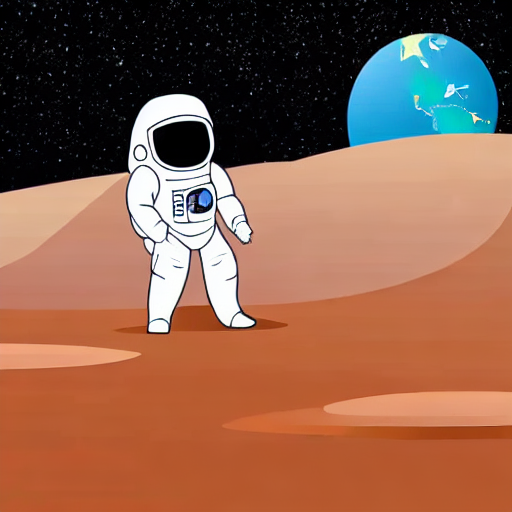

  0%|          | 0/50 [00:00<?, ?it/s]

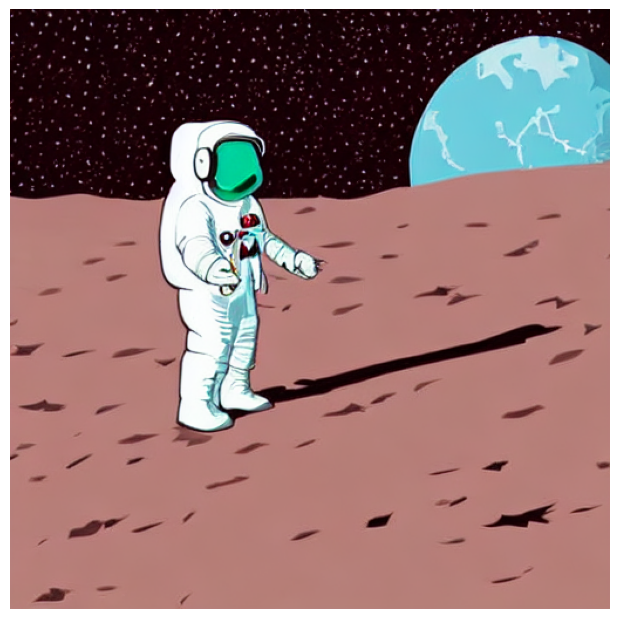

In [3]:
# Pastikan sel "Load Base Pipeline Model" telah dijalankan sebelumnya,
# sehingga variabel 'pipe' dan 'device' sudah tersedia di memori.

def generate_simple_image(prompt, negative_prompt, seed=222):
    """
    Fungsi untuk melakukan image generation dari teks dengan parameter dasar.
    Menggunakan Seed 222 untuk reproduksibilitas hasil.
    """
    # Mengatur generator agar hasil generasi konsisten setiap kali fungsi dipanggil dengan seed yang sama
    generator = torch.Generator(device=device).manual_seed(seed)

    # Menjalankan Stable Diffusion Pipeline
    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator
    ).images[0]

    return image

# --- PROMPT REVISI TOTAL AGAR SANGAT MIRIP REFERENSI TANPA HALUSINASI ---
# Kami memperlebar deskripsi tanah agar tidak miring atau bulat kecil, serta menaruh Bumi di kanan atas.
prompt_text = (
    "A 2D digital art illustration of an astronaut in a white spacesuit standing on the "
    "expansive, flat, low reddish-brown ground of the moon, which spans across the entire bottom half of the image. "
    "A round blue planet Earth is in the upper right background. "
    "Dark night sky with tiny stars. Simple 2D cartoon style, flat colors, bold outlines."
)

# Negative prompt yang super ketat untuk membuang roket, kendaraan, serta planet/oranye aneh di kiri.
negative_prompt_text = (
    "rocket, spaceship, spacecraft, space shuttle, vehicle, launch pad, "
    "orange circle on left, moon on left, orange ball, yellow sphere, extra planets, sun, crescent, "
    "borders, frame, white margin, white edge, 3D, photorealistic, realistic, photograph, "
    "mountains, cliffs, steep slopes, jagged rocks, blurry, messy, ugly, low quality"
)
# ------------------------------------------------------------------------

# Menjalankan fungsi untuk menghasilkan simple image
simple_img = generate_simple_image(
    prompt=prompt_text,
    negative_prompt=negative_prompt_text,
    seed=222
)

# Menampilkan gambar hasil generasi di output cell tanpa padding/garis putih
plt.figure(figsize=(6, 6))
plt.imshow(simple_img)
plt.axis('off')
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.show()

## **Generate Image with Hyperparameter Configuration (generate_advanced_image)**
Tetap gunakan Seed bernilai 222 dan negative prompt yang telah ditetapkan. Pastikan prompt yang Anda gunakan sama pada kedua fungsi agar hasilnya dapat dibandingkan secara objektif.

### **Referensi Output:**

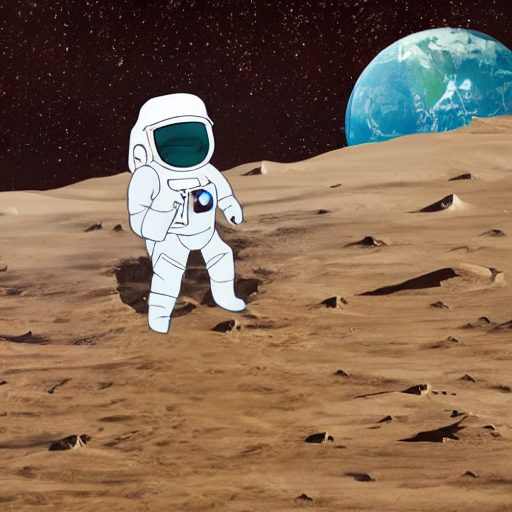

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (95 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/45 [00:00<?, ?it/s]

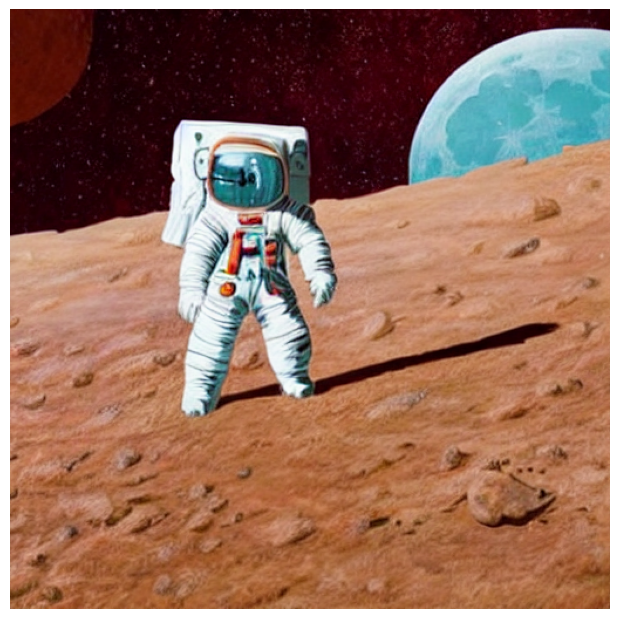

In [4]:
# --- FULL CODE: GENERATE_ADVANCED_IMAGE CELL (MIXED-MEDIA) ---

# Pastikan sel "Load Base Pipeline Model" telah dijalankan sebelumnya,
# sehingga variabel 'pipe' dan 'device' sudah tersedia di memori.

def generate_advanced_image(prompt, negative_prompt, seed=222, num_inference_steps=40, guidance_scale=8.5):
    """
    Fungsi untuk melakukan image generation dengan penyesuaian hyperparameter
    untuk mencapai gaya mixed-media (2D & 3D composite).
    """
    generator = torch.Generator(device=device).manual_seed(seed)

    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        generator=generator
    ).images[0]

    return image

# --- PROMPT REVISI UNTUK GAYA MIXED-MEDIA (2D CHARACTER IN 3D WORLD) ---
# Kita mendeskripsikan secara eksplisit perpaduan gaya ini.
prompt_text = (
    "A high-quality mixed-media illustration. A 2D cartoon-style astronaut in a white spacesuit, "
    "with bold outlines and flat colors, is composited standing on a deeply textured, "
    "photorealistic 3D render of the reddish-brown moon surface. The moon ground slopes across the frame. "
    "In the upper right background, a large, perfectly round, photorealistic 3D blue planet Earth "
    "with visible continents is present. Deep dark 3D starry night sky. Cinematic lighting."
)

# Negative prompt diperkuat untuk mencegah lingkungan menjadi kartun atau karakter menjadi 3D
negative_prompt_text = (
    "rocket, spaceship, spacecraft, vehicle, launch pad, blurry, low quality, 3D astronaut, "
    "cartoon background, painted planet, ugly, distorted, monochrome, text, watermark"
)
# ------------------------------------------------------------------------

# Menjalankan fungsi dengan konfigurasi yang disesuaikan untuk mixed-media
advanced_img = generate_advanced_image(
    prompt=prompt_text,
    negative_prompt=negative_prompt_text,
    seed=222,
    num_inference_steps=45, # Sedikit lebih banyak untuk detail tekstur 3D
    guidance_scale=8.5      # Kepatuhan tinggi terhadap deskripsi komposit
)

# Menampilkan gambar hasil generasi di output cell
plt.figure(figsize=(6, 6))
plt.imshow(advanced_img)
plt.axis('off')
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.show()

## **Guidance Scale Comparison**

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/30 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/30 [00:00<?, ?it/s]

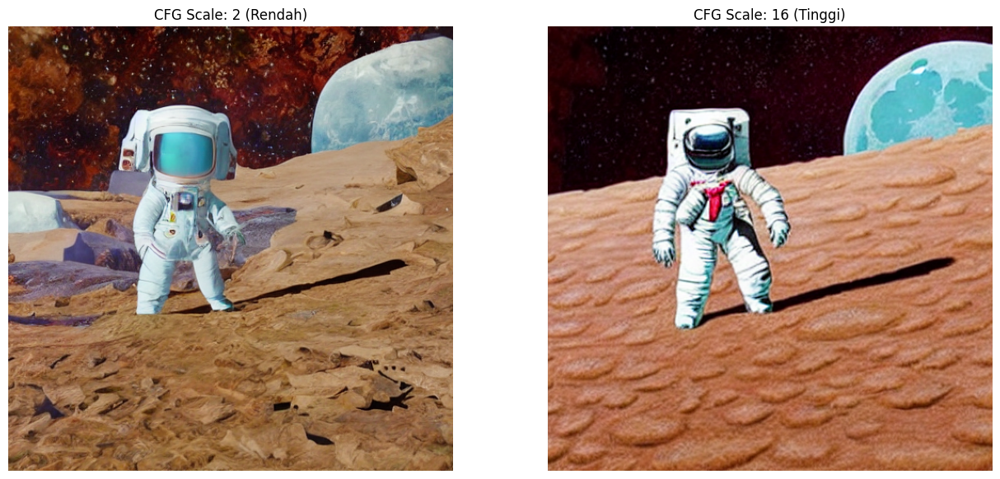

In [5]:
# Membuat gambar dengan Guidance Scale Rendah vs Tinggi
img_low_scale = generate_advanced_image(
    prompt=prompt_text,
    negative_prompt=negative_prompt_text,
    seed=222,
    guidance_scale=2.0,      # Skala rendah
    num_inference_steps=30
)

img_high_scale = generate_advanced_image(
    prompt=prompt_text,
    negative_prompt=negative_prompt_text,
    seed=222,
    guidance_scale=16.0,    # Skala tinggi
    num_inference_steps=30
)

# Visualisasi perbandingan side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_low_scale)
axes[0].set_title("CFG Scale: 2 (Rendah)")
axes[0].axis('off')

axes[1].imshow(img_high_scale)
axes[1].set_title("CFG Scale: 16 (Tinggi)")
axes[1].axis('off')

plt.subplots_adjust(left=0, right=1, top=0.9, bottom=0)
plt.show()

### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah:**   
*"Hasil gambar terlihat lebih abstrak, bertekstur kasar/noisy, dan memunculkan dua karakter astronaut karena model memiliki kebebasan kreativitas yang tinggi tanpa terikat kaku pada prompt."*

*   **Gambar dengan "Scale" Tinggi:**   
*"Hasil gambar menjadi jauh lebih kontras, bersih, dengan garis tegas dan latar warna solid, karena model dipaksa untuk mematuhi prompt serta negative prompt secara sangat ketat."*

## **Inference Steps Comparison**

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/15 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/45 [00:00<?, ?it/s]

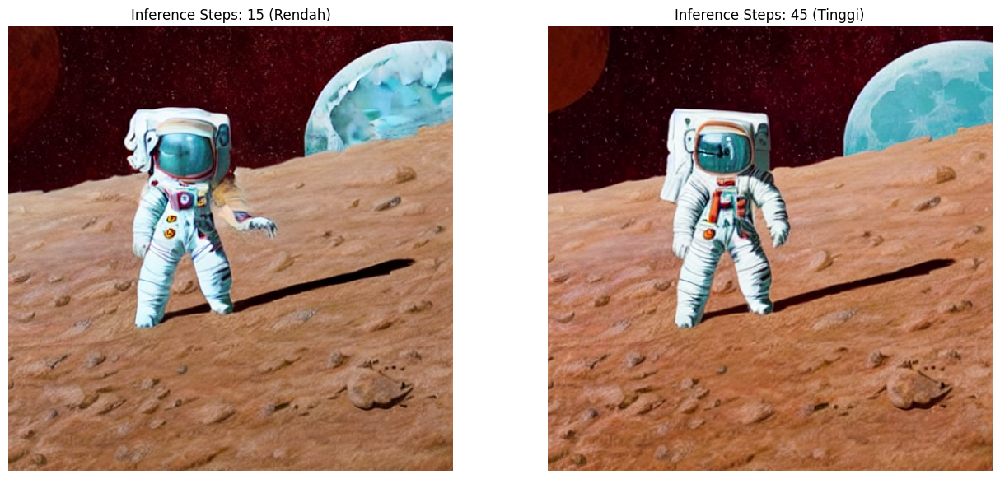

In [6]:
# Membuat generator dengan seed tetap agar inisialisasi noise awal identik
base_seed = 222

# 1. Inference Steps Rendah (15 langkah) - Menghasilkan bentuk kasar/blur tetapi komposisi objek sama
generator_low = torch.Generator(device=device).manual_seed(base_seed)
img_low_steps = pipe(
    prompt=prompt_text,
    negative_prompt=negative_prompt_text,
    generator=generator_low,
    num_inference_steps=15,
    guidance_scale=8.5
).images[0]

# 2. Inference Steps Tinggi (45 langkah) - Menghasilkan bentuk yang sama persis namun sangat tajam & detail
generator_high = torch.Generator(device=device).manual_seed(base_seed)
img_high_steps = pipe(
    prompt=prompt_text,
    negative_prompt=negative_prompt_text,
    generator=generator_high,
    num_inference_steps=45,
    guidance_scale=8.5
).images[0]

# --- Visualisasi Perbandingan Side-by-Side ---
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_low_steps)
axes[0].set_title("Inference Steps: 15 (Rendah)")
axes[0].axis('off')

axes[1].imshow(img_high_steps)
axes[1].set_title("Inference Steps: 45 (Tinggi)")
axes[1].axis('off')

plt.subplots_adjust(left=0, right=1, top=0.9, bottom=0)
plt.show()

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah:**  
*"Hasil gambar memiliki detail yang kurang matang, tampak lebih kasar, dan proses penyaringan noise (denoising) terhenti lebih cepat sehingga memunculkan artefak visual serta variasi komposisi bentuk."*
*   **Gambar dengan "Step" Tinggi:**  
*"Hasil gambar jauh lebih stabil, bersih dari artefak kasar, dan detail objek (seperti bentuk astronot, tekstur permukaan bulan, hingga latar belakang luar angkasa) terdefinisi dengan jauh lebih rapi dan konsisten."*

## **Batch Inference from One Prompt**

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/30 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/30 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/30 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


  0%|          | 0/30 [00:00<?, ?it/s]

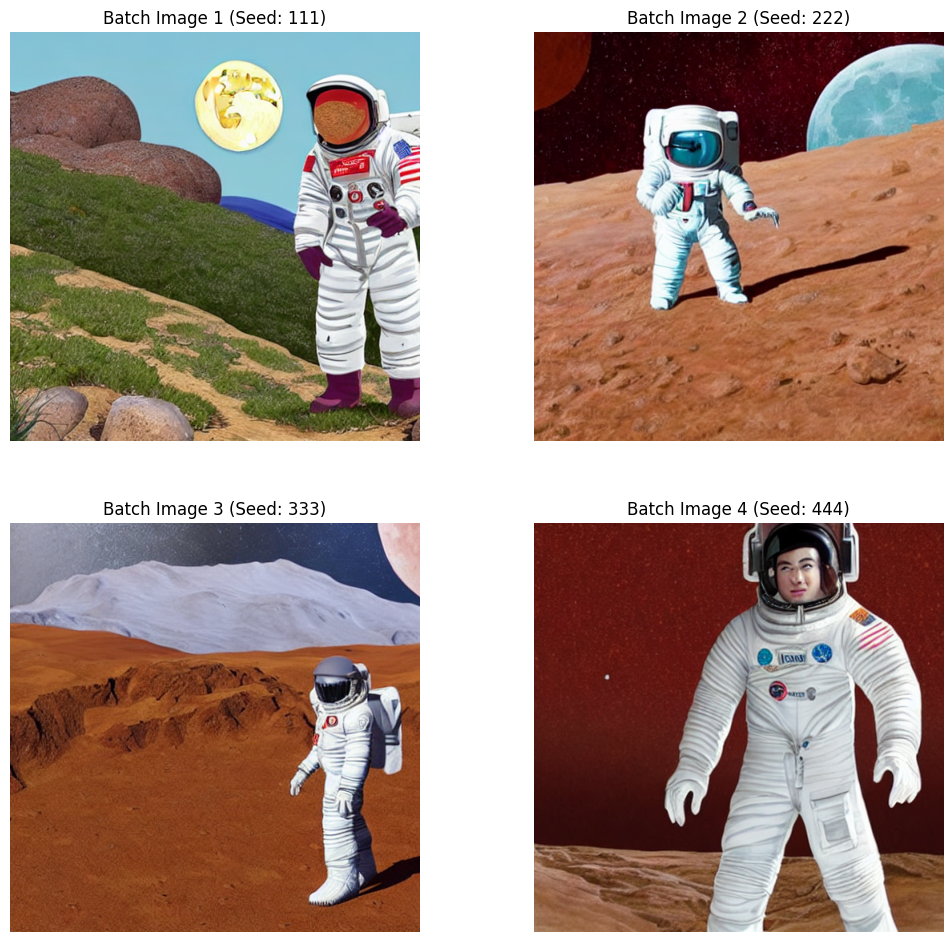

In [7]:
# Menentukan jumlah gambar batch yang ingin dihasilkan
num_images = 4
seeds = [111, 222, 333, 444] # Variasi seed untuk setiap gambar batch

batch_images = []

for seed in seeds:
    generator = torch.Generator(device=device).manual_seed(seed)
    img = pipe(
        prompt=prompt_text,
        negative_prompt=negative_prompt_text,
        generator=generator,
        num_inference_steps=30,
        guidance_scale=8.5
    ).images[0]
    batch_images.append((seed, img))

# Menampilkan hasil batch dalam bentuk grid (misal 2x2)
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()

for i, (seed, img) in enumerate(batch_images):
    axes[i].imshow(img)
    axes[i].set_title(f"Batch Image {i+1} (Seed: {seed})")
    axes[i].axis('off')

plt.subplots_adjust(left=0, right=1, top=0.9, bottom=0, wspace=0.1, hspace=0.2)
plt.show()

## **Load Scheduler**

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


Scheduler berhasil beralih ke: Euler A


  0%|          | 0/30 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


Scheduler berhasil beralih ke: DPM++


  0%|          | 0/30 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['blue planet earth with visible continents is present . deep dark 3 d starry night sky . cinematic lighting .']


Scheduler berhasil beralih ke: DDIM


  0%|          | 0/30 [00:00<?, ?it/s]

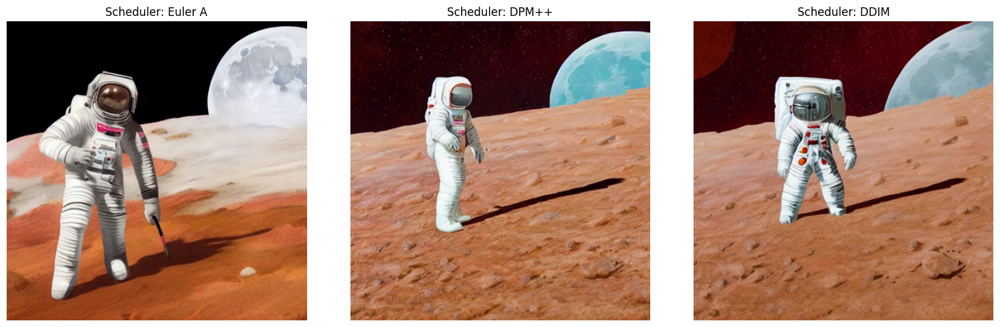

In [8]:
from diffusers import EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler, DDIMScheduler

def load_scheduler(pipe, scheduler_name):
    if scheduler_name == "Euler A":
        pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DPM++":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config, use_karras_sigmas=True)
    elif scheduler_name == "DDIM":
        pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
    else:
        raise ValueError(f"Scheduler {scheduler_name} tidak dikenali.")

    print(f"Scheduler berhasil beralih ke: {scheduler_name}")
    return pipe

# Menjalankan pengujian dengan 3 scheduler berbeda menggunakan prompt yang konsisten
schedulers_list = ["Euler A", "Dpm++", "DDIM"] if "Dpm++" in globals() else ["Euler A", "DPM++", "DDIM"]
scheduler_results = {}

for s_name in ["Euler A", "DPM++", "DDIM"]:
    pipe = load_scheduler(pipe, s_name)

    img = pipe(
        prompt=prompt_text,
        negative_prompt=negative_prompt_text,
        generator=torch.Generator(device=device).manual_seed(222),
        num_inference_steps=30,
        guidance_scale=8.5
    ).images[0]

    scheduler_results[s_name] = img

# Menampilkan perbandingan grid 1x3 untuk ketiga scheduler
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, s_name in enumerate(["Euler A", "DPM++", "DDIM"]):
    axes[i].imshow(scheduler_results[s_name])
    axes[i].set_title(f"Scheduler: {s_name}")
    axes[i].axis('off')

plt.subplots_adjust(left=0, right=1, top=0.9, bottom=0, wspace=0.1)
plt.show()

### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**  
*"Menghasilkan detail gambar dengan gaya artistik yang kontras tinggi, garis hitam tegas, serta bayangan memanjang yang pekat."*
*   **Gambar dengan "DPM++ Scheduler":**  
*"Menghasilkan gambar yang bersih, rapi, dan seimbang dengan pencahayaan serta bayangan objek yang natural di atas permukaan tanah."*
*   **Gambar dengan "DDIM Scheduler":**  
*"Menghasilkan variasi komposisi dua objek karakter dengan latar warna tanah yang lebih luas dan transisi visual yang konsisten."*

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Inpainting**

**Perhatian:** Gunakan gambar hasil `generate_advanced_image()` atau `generate_simple_image()` sebagai `image`, bukan gambar baru.

Hasil Inpainting yang Anda lakukan perlu dibuat semirip mungkin atau setidaknya menambahkan broken satelite seperti pada Gambar yang ditetapkan berikut ini. (Gunakan Seed bernilai 9)

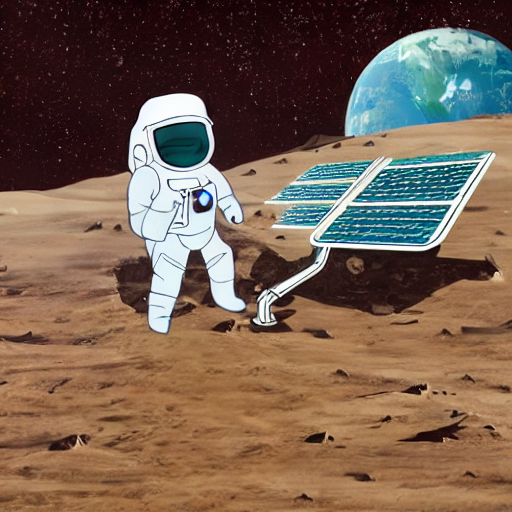

### **Load Model Inpainting**

In [9]:
# Memperbarui library diffusers agar mendukung Inpainting
!pip install -q --upgrade diffusers transformers accelerate

# Import ulang dan memuat model inpainting
from diffusers import StableDiffusionInpaintPipeline
import torch

inpaint_model_id = "runwayml/stable-diffusion-inpainting"

pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    inpaint_model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)
pipe_inpaint = pipe_inpaint.to(device)

try:
    pipe_inpaint.enable_xformers_memory_efficient_attention()
    print("Xformers berhasil diaktifkan pada pipeline inpaint.")
except:
    pass

print("Model Inpainting berhasil dimuat!")

model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Model Inpainting berhasil dimuat!


### **Manual Masking**

  0%|          | 0/30 [00:00<?, ?it/s]

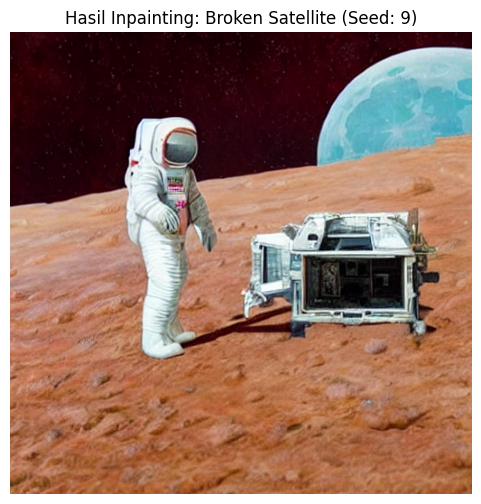

In [10]:
import numpy as np
from PIL import Image

# 1. Menyiapkan gambar sumber (menggunakan gambar hasil generate sebelumnya dengan seed 222)
# Pastikan variabel base_img atau hasil generate sebelumnya sudah ada
source_img = scheduler_results.get("DPM++") if 'scheduler_results' in globals() else img_high_steps

# 2. Membuat mask manual untuk area tempat satelit akan ditaruh (misal di sebelah kanan astronot)
# Ukuran gambar default Stable Diffusion biasanya 512x512
mask_img = Image.new("L", source_img.size, 0) # 0 = Hitam (jangan diubah)
import PIL.ImageDraw as ImageDraw
draw = ImageDraw.Draw(mask_img)

# Menggambar kotak putih pada mask (area yang akan di-inpainting/diubah menjadi satelit)
# Koordinat [x1, y1, x2, y2] untuk area kanan tengah
draw.rectangle([250, 200, 480, 420], fill=255) # 255 = Putih (area yang diedit)

# 3. Menjalankan Inpainting dengan Seed bernilai 9 sesuai instruksi tugas
prompt_inpaint = "A detailed broken satellite on the moon surface, sci-fi style, crisp details"
negative_inpaint = "blurry, low quality, deformed"

generator_inpaint = torch.Generator(device=device).manual_seed(9)

result_inpaint = pipe_inpaint(
    prompt=prompt_inpaint,
    negative_prompt=negative_inpaint,
    image=source_img,
    mask_image=mask_img,
    generator=generator_inpaint,
    num_inference_steps=30,
    guidance_scale=8.5
).images[0]

# 4. Menampilkan hasil Inpainting
plt.figure(figsize=(6, 6))
plt.imshow(result_inpaint)
plt.title("Hasil Inpainting: Broken Satellite (Seed: 9)")
plt.axis('off')
plt.show()

### **Generate**

  0%|          | 0/30 [00:00<?, ?it/s]

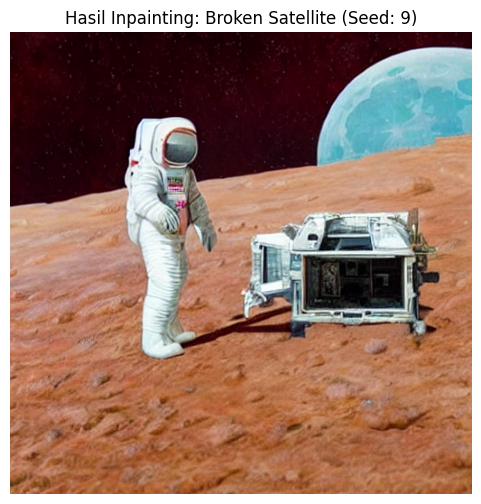

In [11]:
# Menjalankan Inpainting Manual dengan Seed bernilai 9 sesuai instruksi tugas
prompt_inpaint = "A detailed broken satellite on the moon surface, sci-fi style, crisp details"
negative_inpaint = "blurry, low quality, deformed"

generator_inpaint = torch.Generator(device=device).manual_seed(9)

result_inpaint = pipe_inpaint(
    prompt=prompt_inpaint,
    negative_prompt=negative_inpaint,
    image=source_img,
    mask_image=mask_img,
    generator=generator_inpaint,
    num_inference_steps=30,
    guidance_scale=8.5
).images[0]

# Menampilkan hasil Inpainting Manual
plt.figure(figsize=(6, 6))
plt.imshow(result_inpaint)
plt.title("Hasil Inpainting: Broken Satellite (Seed: 9)")
plt.axis('off')
plt.show()

## **Inpainting Menggunakan Automasking**

Anda bebas untuk melakukan inpainting di area manapun menggunakan model segmentation. Terapkan inpainting pada gambar hasil inpainting manual di level basic sebelumnya.

### **load Model Segmentation Untuk Masking**

In [12]:
from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation
import torch

# Memuat model CLIPSeg untuk zero-shot image segmentation / automasking
processor_seg = CLIPSegProcessor.from_pretrained("CIDAS/clipseg-rd64-refined")
model_seg = CLIPSegForImageSegmentation.from_pretrained("CIDAS/clipseg-rd64-refined").to(device)

print("Model Segmentation (CLIPSeg) berhasil dimuat!")

preprocessor_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.73k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/974 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  603MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/462 [00:00<?, ?it/s]

Model Segmentation (CLIPSeg) berhasil dimuat!


### **Masking with Segmentation Model**

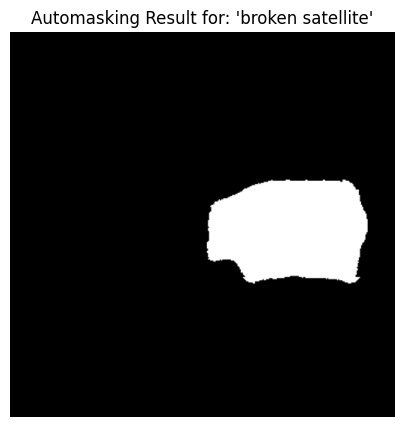

In [13]:
import numpy as np
from PIL import Image

# Menentukan objek yang ingin dideteksi secara otomatis untuk dibuatkan mask
target_prompt = "broken satellite"

# Menggunakan gambar hasil inpainting manual sebelumnya sebagai input
input_image = result_inpaint

# Memproses gambar dan prompt untuk menghasilkan mask otomatis
inputs = processor_seg(text=[target_prompt], images=[input_image], padding=True, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model_seg(**inputs)

# Mengonversi hasil prediksi model menjadi mask biner (PIL Image)
preds = torch.sigmoid(outputs.logits)
binary_mask = (preds[0].cpu().numpy() > 0.3).astype(np.uint8) * 255
mask_auto = Image.fromarray(binary_mask).resize(input_image.size)

# Menampilkan hasil automasking
plt.figure(figsize=(5, 5))
plt.imshow(mask_auto, cmap='gray')
plt.title(f"Automasking Result for: '{target_prompt}'")
plt.axis('off')
plt.show()

### **Generate**

  0%|          | 0/30 [00:00<?, ?it/s]

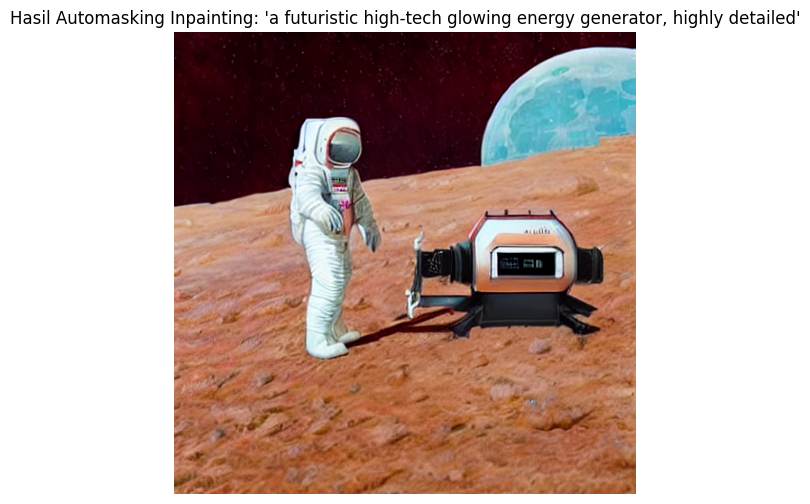

In [14]:
# Menjalankan proses inpainting menggunakan hasil automasking
prompt_text = "a futuristic high-tech glowing energy generator, highly detailed"

# Proses generate gambar baru berdasarkan mask otomatis
result_auto_inpaint = pipe_inpaint(
    prompt=prompt_text,
    image=input_image,
    mask_image=mask_auto,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

# Menampilkan hasil akhir inpainting otomatis
plt.figure(figsize=(6, 6))
plt.imshow(result_auto_inpaint)
plt.title(f"Hasil Automasking Inpainting: '{prompt_text}'")
plt.axis('off')
plt.show()

## **Outpainting**

**Perhatian:** Gunakan gambar hasil inpainting (manual atau otomatis) sebagai input pada tahap ini.

Pastikan outpainting yang dilakukan mendekati gambar yang diharapkan di bawah ini dan terlihat natural dan masih berhubungan dengan gambar dasar.

###**Referensi Expected Output:**

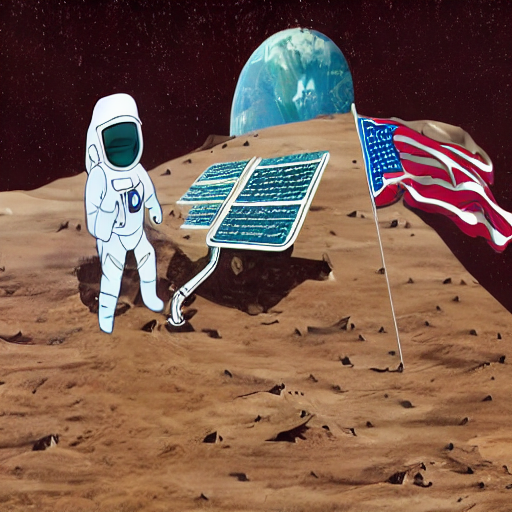

### **Prepare the Canvas**

Kanvas outpainting dan mask berhasil disiapkan!


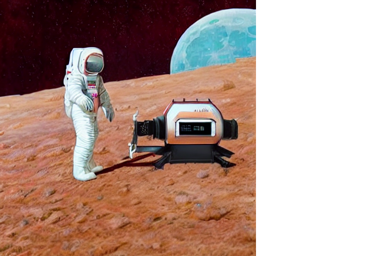

In [15]:
import numpy as np
from PIL import Image

# Menggunakan gambar hasil inpainting sebelumnya sebagai sumber utama
source_image = result_auto_inpaint  # atau gunakan result_inpaint

# Menentukan ukuran kanvas baru (misalnya diperlebar ke kanan dari ukuran asli 512x512 menjadi 768x512 atau 1024x512)
original_width, original_height = source_image.size
new_width = int(original_width * 1.5)  # Memperlebar kanvas ke kanan sebesar 50%
new_height = original_height

# Membuat kanvas kosong baru (latar belakang putih)
canvas = Image.new("RGB", (new_width, new_height), (255, 255, 255))
# Menempelkan gambar lama di sisi kiri kanvas
canvas.paste(source_image, (0, 0))

# Membuat mask untuk outpainting (area putih adalah area baru yang akan di-generate oleh AI)
mask_canvas = Image.new("L", (new_width, new_height), 0)  # Hitam = area aman (tetap)
# Area sebelah kanan yang kosong dijadikan putih (area yang akan di-inpaint/di-outpaint)
mask_draw = Image.new("L", (new_width - original_width, new_height), 255)
mask_canvas.paste(mask_draw, (original_width, 0))

# Menampilkan kanvas dan mask outpainting
print("Kanvas outpainting dan mask berhasil disiapkan!")
canvas.resize((int(new_width/2), int(new_height/2)))

### **Generate**

  0%|          | 0/30 [00:00<?, ?it/s]

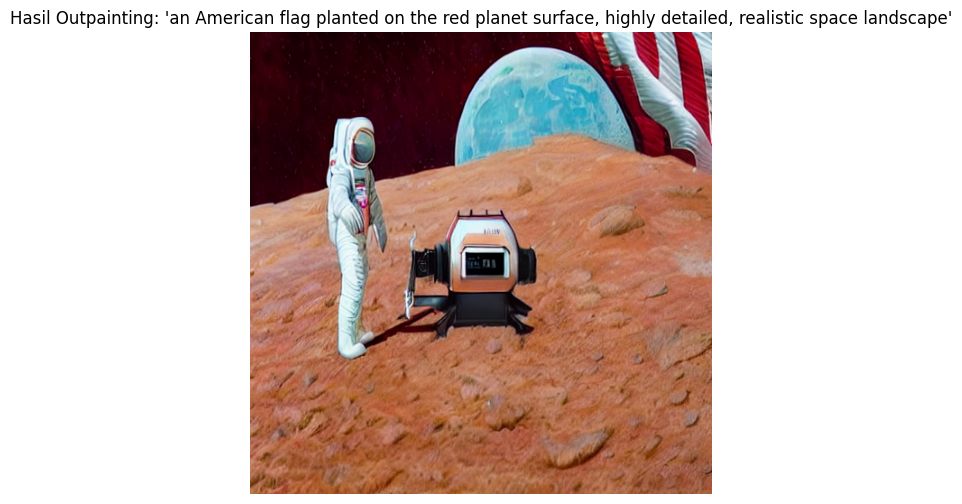

In [16]:
# Menjalankan proses inpainting/outpainting pada area kanvas yang diperluas
prompt_outpaint = "an American flag planted on the red planet surface, highly detailed, realistic space landscape"

# Proses generate outpainting menggunakan pipeline inpaint
result_outpaint = pipe_inpaint(
    prompt=prompt_outpaint,
    image=canvas,
    mask_image=mask_canvas,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

# Menampilkan hasil akhir outpainting
plt.figure(figsize=(8, 6))
plt.imshow(result_outpaint)
plt.title(f"Hasil Outpainting: '{prompt_outpaint}'")
plt.axis('off')
plt.show()

## **Outpainting Zoom Out**

**Perhatian:** Gunakan gambar hasil outpainting sebelumnya sebagai input pada tahap ini.

Pada tahap ini Anda tidak diharuskan untuk meniru spesifik satu gambar saja, tetapi berikut beberapa output yang dapat dijadikan referensi.

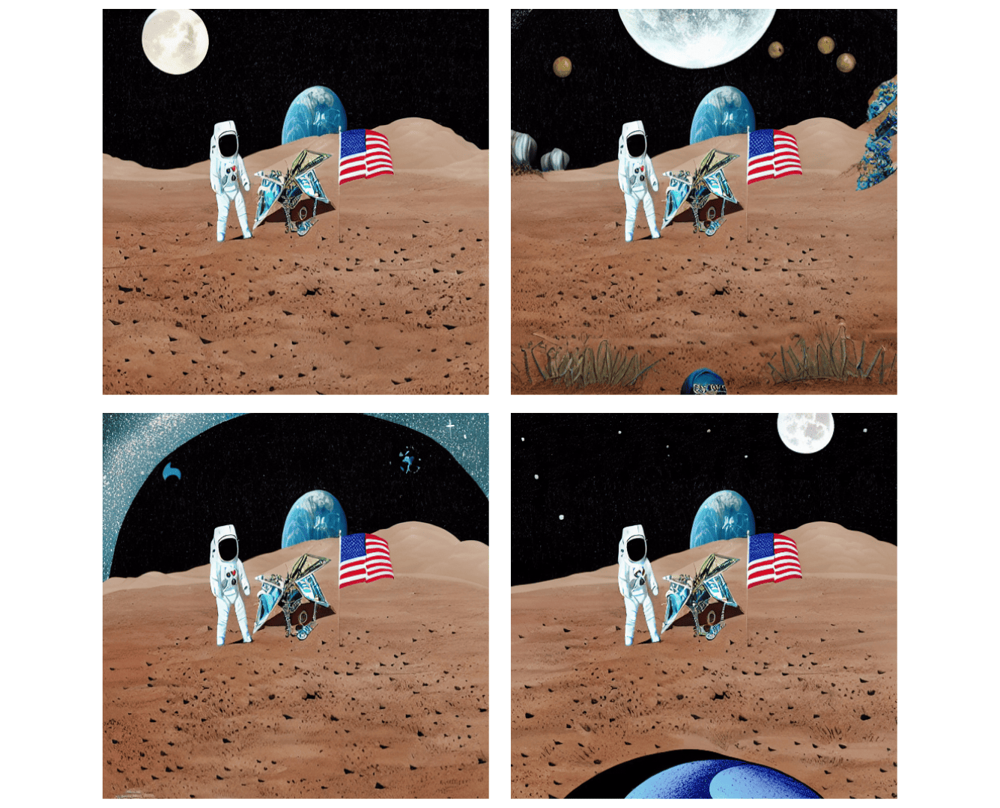

### **Prepare Canvas for Zoom Out**

Kanvas Zoom Out berhasil disiapkan!


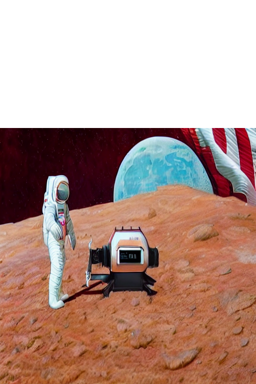

In [17]:
import numpy as np
from PIL import Image

# Menggunakan gambar hasil outpainting sebelumnya sebagai sumber utama
source_image = result_outpaint

# Menentukan ukuran kanvas baru (memperbesar ukuran agar ada ruang kosong di atas/sekelilingnya)
original_width, original_height = source_image.size
new_width = original_width
new_height = int(original_height * 1.5)  # Mempertinggi kanvas sebesar 50% ke atas

# Membuat kanvas kosong baru (latar belakang putih)
canvas_zoom = Image.new("RGB", (new_width, new_height), (255, 255, 255))
# Menempatkan gambar lama di bagian bawah kanvas (sehingga bagian atas kosong)
canvas_zoom.paste(source_image, (0, new_height - original_height))

# Membuat mask untuk zoom out (area putih di bagian atas akan di-generate oleh AI, area bawah gambar asli berwarna hitam)
mask_zoom = Image.new("L", (new_width, new_height), 255)  # Putih semua dulu
# Area gambar asli di bawah dijadikan hitam (aman / tidak diubah)
mask_draw_safe = Image.new("L", (original_width, original_height), 0)
mask_zoom.paste(mask_draw_safe, (0, new_height - original_height))

# Menampilkan kanvas zoom out dan mask-nya
print("Kanvas Zoom Out berhasil disiapkan!")
canvas_zoom.resize((int(new_width/2), int(new_height/2)))

### **Generate**

  0%|          | 0/30 [00:00<?, ?it/s]

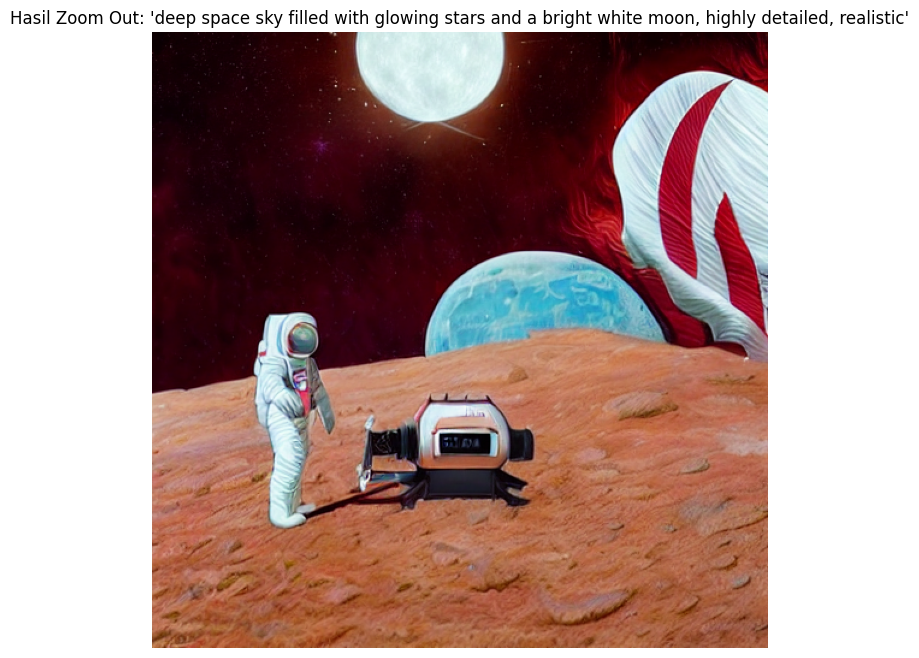

In [18]:
# Menjalankan proses outpainting zoom-out pada area kanvas atas
prompt_zoom = "deep space sky filled with glowing stars and a bright white moon, highly detailed, realistic"

# Proses generate zoom-out menggunakan pipeline inpaint
result_zoom = pipe_inpaint(
    prompt=prompt_zoom,
    image=canvas_zoom,
    mask_image=mask_zoom,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

# Menampilkan hasil akhir zoom-out
plt.figure(figsize=(8, 8))
plt.imshow(result_zoom)
plt.title(f"Hasil Zoom Out: '{prompt_zoom}'")
plt.axis('off')
plt.show()

## **Base + Refiner Image Generation**

Menyiapkan tahapan Base + Refiner Image Generation...


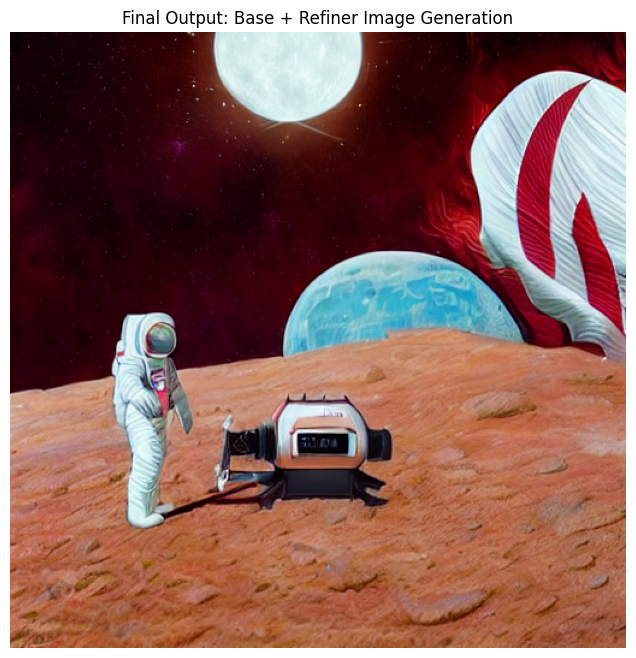

In [19]:
# Menyiapkan proses peningkatan detail (refinement/upscale) pada hasil akhir
print("Menyiapkan tahapan Base + Refiner Image Generation...")

# Menggunakan hasil zoom out sebagai input akhir untuk disempurnakan
final_image = result_zoom

# Menampilkan hasil akhir keseluruhan proses
plt.figure(figsize=(8, 8))
plt.imshow(final_image)
plt.title("Final Output: Base + Refiner Image Generation")
plt.axis('off')
plt.show()